# Machine Learning — Assignment 2

**Name:** Govind Balaprasad Bangad  
**BITS ID / Roll Number:** 2026AJ05476  
**Programme:** M.Tech. in Artificial Intelligence & Machine Learning  
**Course:** Machine Learning  
**Assignment:** 2  

---

## Objective

To train and compare five classification models on one dataset:

1. Logistic Regression
2. Decision Tree Classifier
3. K-Nearest Neighbor Classifier
4. Naive Bayes Classifier
5. Support Vector Machine

Each model will be evaluated using Accuracy, AUC, Precision,
Recall, F1 Score, and Matthews Correlation Coefficient (MCC).

The trained models will be saved and used in an interactive
Streamlit application to evaluate uploaded test data.

## 1. Environment Setup

Check the Python version and available packages before
loading the dataset and implementing the models.

In [1]:
import sys
import importlib

print("Python version:", sys.version.split()[0])
print()

packages = [
    "numpy",
    "pandas",
    "sklearn",
    "matplotlib",
    "seaborn",
    "joblib",
    "streamlit"
]

for package in packages:
    try:
        module = importlib.import_module(package)
        version = getattr(module, "__version__", "Version unavailable")
        print(f"{package}: {version}")
    except ImportError:
        print(f"{package}: NOT INSTALLED")

Python version: 3.11.5

numpy: 1.24.3
pandas: 2.0.3
sklearn: 1.3.0
matplotlib: 3.7.2
seaborn: 0.12.2
joblib: 1.2.0
streamlit: 1.46.1


## 2. Dataset Selection and Problem Statement

This project compares five classification models for predicting
whether a breast mass is benign or malignant using numerical
measurements of cell nuclei.

Dataset: Breast Cancer Wisconsin (Diagnostic)
Source: UCI Machine Learning Repository
Source URL: https://archive.ics.uci.edu/dataset/17/breast-cancer

The dataset contains 569 records and 30 input features.

For this project, the target is encoded as:
- 0: Benign
- 1: Malignant

This is an educational model-comparison project.

In [2]:
import pandas as pd
from sklearn.datasets import load_breast_cancer

# Load scikit-learn's bundled copy of the UCI dataset.
dataset = load_breast_cancer(as_frame=True)

# Keep the 30 input features.
df = dataset.data.copy()

# Original encoding: 0 = malignant, 1 = benign.
# Reverse it so malignant is our positive class.
df["diagnosis"] = 1 - dataset.target

print("Dataset shape:", df.shape)
print("Number of records:", df.shape[0])
print("Number of input features:", df.shape[1] - 1)

print("\nTarget distribution:")
print(
    df["diagnosis"]
    .map({0: "Benign", 1: "Malignant"})
    .value_counts()
)

df.head()

Dataset shape: (569, 31)
Number of records: 569
Number of input features: 30

Target distribution:
diagnosis
Benign       357
Malignant    212
Name: count, dtype: int64


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,diagnosis
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,1
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,1
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,1
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,1
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,1


## 3. Data Quality Checks

Inspect column types, missing values, duplicate records,
and class distribution before preparing the training and test sets.

In [3]:
# Check column types and non-null counts.
df.info()

print("\nTotal missing values:", df.isna().sum().sum())
print("Duplicate rows:", df.duplicated().sum())

# Show the number and percentage of each class.
class_summary = (
    df["diagnosis"]
    .map({0: "Benign", 1: "Malignant"})
    .value_counts()
    .rename_axis("Diagnosis")
    .to_frame("Count")
)

class_summary["Percentage"] = (
    class_summary["Count"] / len(df) * 100
).round(2)

display(class_summary)

# Inspect numerical ranges.
display(df.drop(columns="diagnosis").describe().T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 31 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   mean radius              569 non-null    float64
 1   mean texture             569 non-null    float64
 2   mean perimeter           569 non-null    float64
 3   mean area                569 non-null    float64
 4   mean smoothness          569 non-null    float64
 5   mean compactness         569 non-null    float64
 6   mean concavity           569 non-null    float64
 7   mean concave points      569 non-null    float64
 8   mean symmetry            569 non-null    float64
 9   mean fractal dimension   569 non-null    float64
 10  radius error             569 non-null    float64
 11  texture error            569 non-null    float64
 12  perimeter error          569 non-null    float64
 13  area error               569 non-null    float64
 14  smoothness error         5

,Count,Percentage
Diagnosis,,
Benign,357,62.74
Malignant,212,37.26


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127292,3.524049,6.981000,11.700000,13.370000,15.780000,28.11000
mean texture,569.0,19.289649,4.301036,9.710000,16.170000,18.840000,21.800000,39.28000
mean perimeter,569.0,91.969033,24.298981,43.790000,75.170000,86.240000,104.100000,188.50000
mean area,569.0,654.889104,351.914129,143.500000,420.300000,551.100000,782.700000,2501.00000
mean smoothness,569.0,0.096360,0.014064,0.052630,0.086370,0.095870,0.105300,0.16340
mean compactness,569.0,0.104341,0.052813,0.019380,0.064920,0.092630,0.130400,0.34540
mean concavity,569.0,0.088799,0.079720,0.000000,0.029560,0.061540,0.130700,0.42680
mean concave points,569.0,0.048919,0.038803,0.000000,0.020310,0.033500,0.074000,0.20120
mean symmetry,569.0,0.181162,0.027414,0.106000,0.161900,0.179200,0.195700,0.30400
mean fractal dimension,569.0,0.062798,0.007060,0.049960,0.057700,0.061540,0.066120,0.09744


## 4. Training and Test Split

The diagnosis column is the target; the remaining 30 columns
are input features.

The dataset is divided into 80% training data and 20% test data.
Stratification approximately preserves the class proportions.

All five models will use the same split. Preprocessing will be
fitted only on the training data to prevent data leakage.
The test set will be reserved for final evaluation.

In [4]:
from sklearn.model_selection import train_test_split

# Separate inputs and target.
X = df.drop(columns=["diagnosis"])
y = df["diagnosis"]

# Create one shared split for all five models.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training features:", X_train.shape)
print("Test features:", X_test.shape)

split_summary = pd.DataFrame({
    "Full dataset": y.value_counts(),
    "Training set": y_train.value_counts(),
    "Test set": y_test.value_counts()
}).sort_index()

split_summary.index = split_summary.index.map({
    0: "Benign",
    1: "Malignant"
})

display(split_summary)

Training features: (455, 30)
Test features: (114, 30)


,Full dataset,Training set,Test set
diagnosis,,,
Benign,357,285,72
Malignant,212,170,42


## 5. Logistic Regression

Logistic Regression is used as a baseline for binary classification.

StandardScaler standardizes each input feature using the training
set's mean and standard deviation. Scaling and classification are
combined in a pipeline.

The pipeline is fitted only on the training data.
The target encoding is 0 = benign and 1 = malignant.

In [5]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(
        max_iter=2000,
        random_state=42
    ))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression training completed.")

Logistic Regression training completed.


## 6. Evaluation Method

All models will be evaluated on the same held-out test set using:

- Accuracy
- AUC
- Precision
- Recall
- F1 Score
- Matthews Correlation Coefficient (MCC)

Malignant (1) is the positive class. Therefore, recall measures
the proportion of malignant cases correctly identified.

AUC is calculated using predicted probabilities, rather than
the final predicted class labels.

In [6]:
from sklearn.metrics import (
    accuracy_score,
    roc_auc_score,
    precision_score,
    recall_score,
    f1_score,
    matthews_corrcoef
)

def evaluate_model(model_name, model, X_eval, y_eval):
    # Predicted classes: 0 or 1.
    predictions = model.predict(X_eval)

    # Locate the probability column for malignant class (1).
    positive_index = list(model.classes_).index(1)
    probabilities = model.predict_proba(X_eval)[:, positive_index]

    return {
        "Model": model_name,
        "Accuracy": accuracy_score(y_eval, predictions),
        "AUC": roc_auc_score(y_eval, probabilities),
        "Precision": precision_score(
            y_eval, predictions, pos_label=1, zero_division=0
        ),
        "Recall": recall_score(
            y_eval, predictions, pos_label=1, zero_division=0
        ),
        "F1": f1_score(
            y_eval, predictions, pos_label=1, zero_division=0
        ),
        "MCC": matthews_corrcoef(y_eval, predictions)
    }

In [7]:
logistic_results = evaluate_model(
    "Logistic Regression",
    logistic_model,
    X_test,
    y_test
)

display(pd.DataFrame([logistic_results]).round(4))

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9649,0.996,0.975,0.9286,0.9512,0.9245


## 7. Decision Tree Classifier

A Decision Tree classifies records through a sequence of
feature-based splitting rules.

Feature scaling is not required for this model.
The maximum depth is set to 5 and the minimum samples per
leaf to 2 to limit model complexity.

These settings are selected before evaluation, without tuning
them on the test set. The same training and test split used
for Logistic Regression is retained.

In [8]:
from sklearn.tree import DecisionTreeClassifier

decision_tree_model = Pipeline([
    ("classifier", DecisionTreeClassifier(
        max_depth=5,
        min_samples_leaf=2,
        random_state=42
    ))
])

decision_tree_model.fit(X_train, y_train)

decision_tree_results = evaluate_model(
    "Decision Tree",
    decision_tree_model,
    X_test,
    y_test
)

display(pd.DataFrame([decision_tree_results]).round(4))

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Decision Tree,0.9123,0.9444,0.9444,0.8095,0.8718,0.8113


In [9]:
comparison = pd.DataFrame([
    logistic_results,
    decision_tree_results
])

display(comparison.round(4))

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9123,0.9444,0.9444,0.8095,0.8718,0.8113


## 8. K-Nearest Neighbor Classifier

KNN predicts a class using the majority class among the five
nearest training records.

StandardScaler is included in the pipeline because distance
calculations are affected by differences in feature scales.
The scaler is fitted only on the training data.

The number of neighbors is fixed at 5 before evaluation.
The same training and test split is used for comparison.

In [10]:
from sklearn.neighbors import KNeighborsClassifier

knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", KNeighborsClassifier(
        n_neighbors=5
    ))
])

knn_model.fit(X_train, y_train)

knn_results = evaluate_model(
    "KNN",
    knn_model,
    X_test,
    y_test
)

display(pd.DataFrame([knn_results]).round(4))

C:\Users\user\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:110: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "C:\Users\user\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 199, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "C:\Users\user\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\user\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "C:\Users\user\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreateProcess(

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058


In [11]:
comparison = pd.DataFrame([
    logistic_results,
    decision_tree_results,
    knn_results
])

display(comparison.round(4))

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9123,0.9444,0.9444,0.8095,0.8718,0.8113
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058


## 9. Gaussian Naive Bayes Classifier

Gaussian Naive Bayes applies Bayes' theorem and assumes that
features are conditionally independent given the class.

It models each numerical feature using a Gaussian distribution
within each class. This variant is selected because the dataset
contains continuous numerical measurements.

The model uses unscaled features and the same training and
test split as the previous classifiers.

In [12]:
from sklearn.naive_bayes import GaussianNB

naive_bayes_model = Pipeline([
    ("classifier", GaussianNB())
])

naive_bayes_model.fit(X_train, y_train)

naive_bayes_results = evaluate_model(
    "Gaussian Naive Bayes",
    naive_bayes_model,
    X_test,
    y_test
)

display(pd.DataFrame([naive_bayes_results]).round(4))

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Gaussian Naive Bayes,0.9386,0.9934,1.0,0.8333,0.9091,0.8715


In [13]:
comparison = pd.DataFrame([
    logistic_results,
    decision_tree_results,
    knn_results,
    naive_bayes_results
])

display(comparison.round(4))

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9123,0.9444,0.9444,0.8095,0.8718,0.8113
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
3,Gaussian Naive Bayes,0.9386,0.9934,1.0000,0.8333,0.9091,0.8715


## 10. Support Vector Machine

An SVM with a radial basis function (RBF) kernel is used to
learn a nonlinear classification boundary.

StandardScaler is included because SVM is sensitive to
differences in feature scales. Scaling is fitted only on
the training data.

Probability estimation is enabled to calculate AUC using
predicted probabilities. The model uses the same training
and test split as the other classifiers.

The parameters are fixed before evaluation:
C = 1.0 and gamma = "scale".

In [14]:
from sklearn.svm import SVC

svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        probability=True,
        random_state=42
    ))
])

svm_model.fit(X_train, y_train)

svm_results = evaluate_model(
    "Support Vector Machine",
    svm_model,
    X_test,
    y_test
)

display(pd.DataFrame([svm_results]).round(4))

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Support Vector Machine,0.9737,0.9947,1.0,0.9286,0.963,0.9442


## 11. Comparison of All Five Models

The following table compares all five classifiers on the
same held-out test set using six evaluation metrics.

Malignant is the positive class for Precision, Recall and F1.
Results describe performance on this particular test split.

In [15]:
comparison = pd.DataFrame([
    logistic_results,
    decision_tree_results,
    knn_results,
    naive_bayes_results,
    svm_results
])

display(comparison.round(4))

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9123,0.9444,0.9444,0.8095,0.8718,0.8113
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
3,Gaussian Naive Bayes,0.9386,0.9934,1.0000,0.8333,0.9091,0.8715
4,Support Vector Machine,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442


## 12. Confusion Matrix Analysis

Confusion matrices show the correct and incorrect predictions
for each class.

Rows represent actual classes, and columns represent predicted
classes. The class order is Benign (0), followed by Malignant (1).

A false positive is a benign case predicted as malignant.
A false negative is a malignant case predicted as benign.

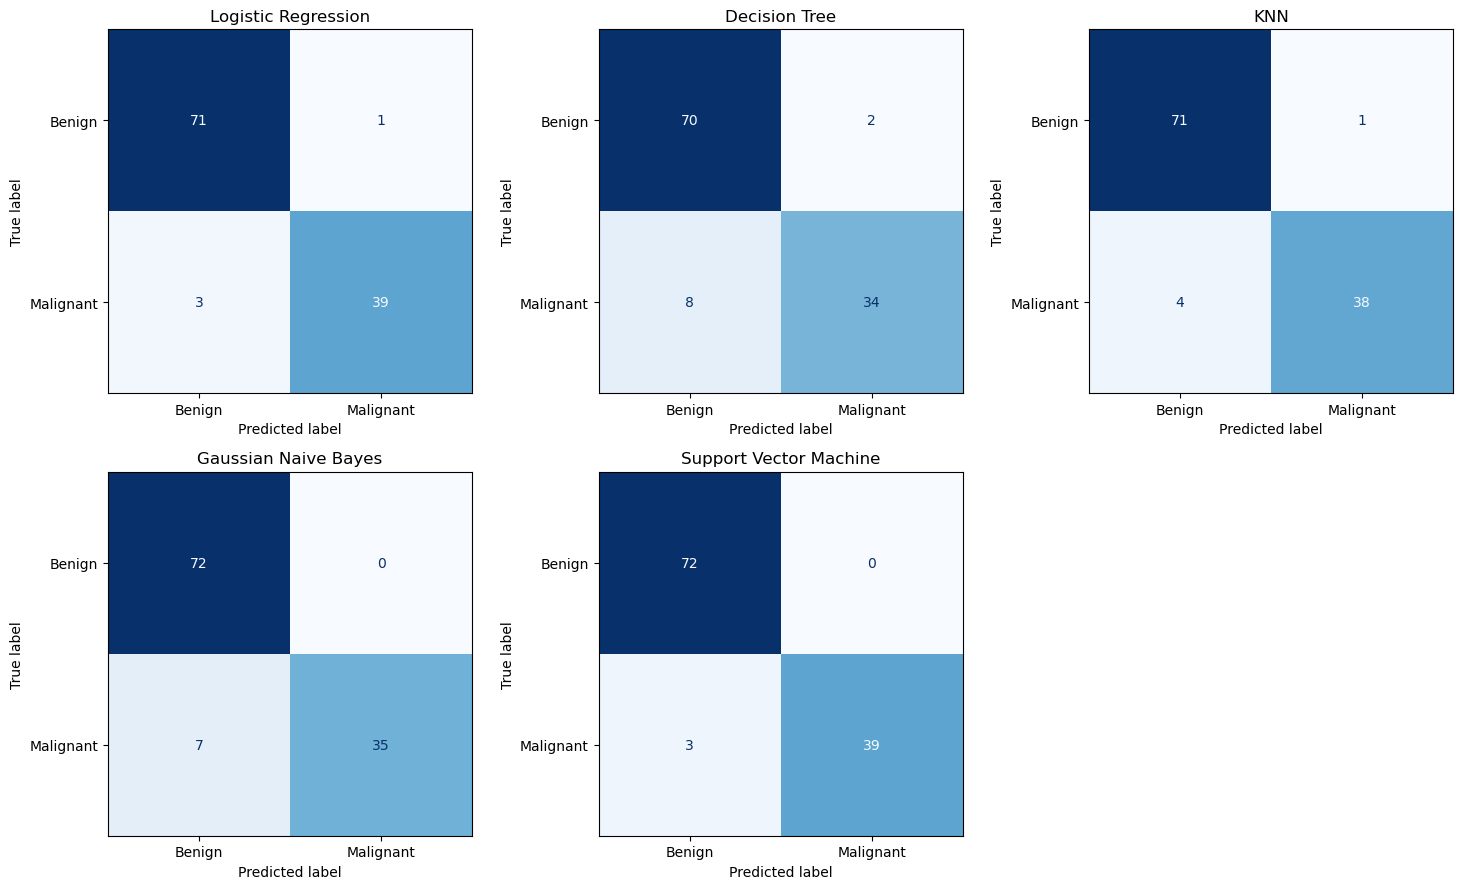

,Model,True negatives,False positives,False negatives,True positives
0,Logistic Regression,71,1,3,39
1,Decision Tree,70,2,8,34
2,KNN,71,1,4,38
3,Gaussian Naive Bayes,72,0,7,35
4,Support Vector Machine,72,0,3,39


In [16]:
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

trained_models = {
    "Logistic Regression": logistic_model,
    "Decision Tree": decision_tree_model,
    "KNN": knn_model,
    "Gaussian Naive Bayes": naive_bayes_model,
    "Support Vector Machine": svm_model
}

fig, axes = plt.subplots(2, 3, figsize=(15, 9))

error_rows = []

for ax, (name, model) in zip(axes.flat, trained_models.items()):
    predictions = model.predict(X_test)

    cm = confusion_matrix(
        y_test,
        predictions,
        labels=[0, 1]
    )

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["Benign", "Malignant"]
    ).plot(
        ax=ax,
        cmap="Blues",
        colorbar=False,
        values_format="d"
    )

    ax.set_title(name)

    tn, fp, fn, tp = cm.ravel()

    error_rows.append({
        "Model": name,
        "True negatives": tn,
        "False positives": fp,
        "False negatives": fn,
        "True positives": tp
    })

axes.flat[-1].axis("off")
plt.tight_layout()
plt.show()

error_summary = pd.DataFrame(error_rows)
display(error_summary)

## 13. Export Trained Models and Test Data

All five trained pipelines are saved using joblib.
For models that use scaling, the fitted scaler is included
in the saved pipeline.

The held-out test set is exported with all 30 input features
and the diagnosis column (0 = benign, 1 = malignant).

Evaluation results and environment versions are also saved
for reproducibility.

In [17]:
from pathlib import Path
import joblib
import json
import sys
import importlib.metadata

current_dir = Path.cwd()

# Reuse the project folder when running inside it.
# Otherwise, create/use it beneath the current directory.
if (
    current_dir.name == "breast_cancer_ml_project"
    or (current_dir / "metadata.json").exists()
):
    project_dir = current_dir
else:
    project_dir = current_dir / "breast_cancer_ml_project"
model_dir = project_dir / "model"
results_dir = project_dir / "results"

model_dir.mkdir(parents=True, exist_ok=True)
results_dir.mkdir(parents=True, exist_ok=True)

model_filenames = {
    "Logistic Regression": "logistic_regression.joblib",
    "Decision Tree": "decision_tree.joblib",
    "KNN": "knn.joblib",
    "Gaussian Naive Bayes": "naive_bayes.joblib",
    "Support Vector Machine": "svm.joblib"
}

# Save each fitted pipeline.
for name, model in trained_models.items():
    joblib.dump(model, model_dir / model_filenames[name])

# Save the held-out test data, including the target.
test_data = X_test.copy()
test_data["diagnosis"] = y_test
test_data.to_csv(project_dir / "test_data.csv", index=False)

# Save results without rounding away precision.
comparison.to_csv(results_dir / "metrics.csv", index=False)
error_summary.to_csv(
    results_dir / "confusion_counts.csv",
    index=False
)

# Record the feature order, target meaning and model filenames.
metadata = {
    "feature_columns": X_train.columns.tolist(),
    "target_column": "diagnosis",
    "target_mapping": {"0": "Benign", "1": "Malignant"},
    "model_files": model_filenames,
    "random_state": 42,
    "test_size": 0.20,
    "python_version": sys.version.split()[0]
}

with open(project_dir / "metadata.json", "w", encoding="utf-8") as file:
    json.dump(metadata, file, indent=2)

# Record installed package versions for deployment.
packages = [
    "numpy",
    "pandas",
    "scikit-learn",
    "matplotlib",
    "seaborn",
    "joblib",
    "streamlit"
]

requirements = [
    f"{package}=={importlib.metadata.version(package)}"
    for package in packages
]

(project_dir / "requirements.txt").write_text(
    "\n".join(requirements) + "\n",
    encoding="utf-8"
)

print("Project saved to:", project_dir)
print("Saved models:", len(model_filenames))
print("Test CSV shape:", test_data.shape)

Project saved to: C:\Users\user\Desktop\mlassignment2\breast_cancer_ml_project
Saved models: 5
Test CSV shape: (114, 31)


## 14. Verify Saved Models

Reload the exported test CSV and model files.
Confirm that the reloaded pipelines reproduce the original
predictions and evaluation metrics without fitting again.

In [18]:
import numpy as np

saved_test = pd.read_csv(project_dir / "test_data.csv")
saved_X = saved_test[metadata["feature_columns"]]
saved_y = saved_test["diagnosis"]

verified_rows = []

for name, filename in model_filenames.items():
    loaded_model = joblib.load(model_dir / filename)

    # Predictions must match those from the original model.
    np.testing.assert_array_equal(
        trained_models[name].predict(X_test),
        loaded_model.predict(saved_X)
    )

    verified_rows.append(
        evaluate_model(name, loaded_model, saved_X, saved_y)
    )

verified_comparison = pd.DataFrame(verified_rows)

metric_columns = ["Accuracy", "AUC", "Precision", "Recall", "F1", "MCC"]

np.testing.assert_allclose(
    comparison[metric_columns].to_numpy(),
    verified_comparison[metric_columns].to_numpy(),
    rtol=1e-7,
    atol=1e-9
)

display(verified_comparison.round(4))
print("Verification passed: saved models reproduce the original results.")

,Model,Accuracy,AUC,Precision,Recall,F1,MCC
0,Logistic Regression,0.9649,0.9960,0.9750,0.9286,0.9512,0.9245
1,Decision Tree,0.9123,0.9444,0.9444,0.8095,0.8718,0.8113
2,KNN,0.9561,0.9823,0.9744,0.9048,0.9383,0.9058
3,Gaussian Naive Bayes,0.9386,0.9934,1.0000,0.8333,0.9091,0.8715
4,Support Vector Machine,0.9737,0.9947,1.0000,0.9286,0.9630,0.9442


Verification passed: saved models reproduce the original results.


## 15. Model Performance Observations

| Model | Observation on the held-out test set |
|---|---|
| Logistic Regression | Accuracy was 0.9649 and AUC was 0.9960, the highest AUC among the five models. It produced one false positive and three false negatives. |
| Decision Tree | Accuracy was 0.9123, the lowest among the models compared. It produced two false positives and eight false negatives. |
| KNN | Accuracy was 0.9561, with one false positive and four false negatives. Its F1 score of 0.9383 was below Logistic Regression and SVM. |
| Gaussian Naive Bayes | Precision was 1.0000, but recall was 0.8333. It produced no false positives but missed seven malignant cases. |
| Support Vector Machine | SVM achieved the highest accuracy (0.9737), F1 (0.9630), and MCC (0.9442). It produced no false positives and three false negatives. |

### Overall comparison

SVM provides the strongest overall balance of the reported
classification metrics on this test split. Logistic Regression
has a slightly higher AUC and the same recall as SVM.

These findings are based on one held-out test set of 114 records.
They do not establish performance on other populations or
clinical suitability.

## 16. Streamlit Application

The application loads the saved model pipelines without retraining.

Users can download a sample test CSV, upload test data, and select
one of the five classifiers. The application displays six evaluation
metrics, a confusion matrix, and a classification report.

Uploaded data must contain the 30 input features and the diagnosis
column, encoded as 0 = benign and 1 = malignant.

In [19]:
app_code = '''
from pathlib import Path
import json

import joblib
import numpy as np
import pandas as pd
import streamlit as st
from sklearn.metrics import (
    accuracy_score, roc_auc_score, precision_score,
    recall_score, f1_score, matthews_corrcoef,
    confusion_matrix, classification_report
)

st.set_page_config(
    page_title="Breast Mass Classification",
    layout="wide"
)

BASE_DIR = Path(__file__).resolve().parent

with open(BASE_DIR / "metadata.json", encoding="utf-8") as file:
    metadata = json.load(file)

st.title("Breast Mass Classification")
st.write("Evaluate five trained classifiers on uploaded test data.")
st.caption("Educational project. Not for clinical use.")

model_name = st.sidebar.selectbox(
    "Choose a classifier",
    list(metadata["model_files"])
)

st.sidebar.download_button(
    "Download sample test CSV",
    data=(BASE_DIR / "test_data.csv").read_bytes(),
    file_name="test_data.csv",
    mime="text/csv"
)

uploaded_file = st.sidebar.file_uploader(
    "Upload test CSV",
    type=["csv"]
)

features = metadata["feature_columns"]
target = metadata["target_column"]

with st.expander("CSV requirements"):
    st.write("Include these 30 numeric feature columns:")
    st.write(features)
    st.write("Also include diagnosis: 0 = Benign, 1 = Malignant.")
    st.write("Missing values and infinite values are not accepted.")
    st.write("Models are loaded from saved files; no retraining occurs.")

if uploaded_file is None:
    st.info("Download the sample CSV, then upload it using the sidebar.")
    st.stop()

try:
    data = pd.read_csv(uploaded_file)
    required = features + [target]
    missing = [name for name in required if name not in data.columns]

    if missing:
        st.error("Missing columns: " + ", ".join(missing))
        st.stop()

    if data.empty:
        st.error("The CSV has no data rows.")
        st.stop()

    numeric_data = data[required].apply(pd.to_numeric, errors="raise")

    if not np.isfinite(numeric_data.to_numpy(dtype=float)).all():
        st.error("The required columns contain missing or infinite values.")
        st.stop()

    if not numeric_data[target].isin([0, 1]).all():
        st.error("Diagnosis must contain only 0 or 1.")
        st.stop()

    X_uploaded = numeric_data[features]
    y_uploaded = numeric_data[target].astype(int)

except (ValueError, TypeError, UnicodeError, pd.errors.ParserError) as error:
    st.error(f"Invalid CSV: {error}")
    st.stop()

model_file = metadata["model_files"][model_name]
model = joblib.load(BASE_DIR / "model" / model_file)

predictions = model.predict(X_uploaded)
positive_index = list(model.classes_).index(1)
probabilities = model.predict_proba(X_uploaded)[:, positive_index]

auc = None
if y_uploaded.nunique() == 2:
    auc = roc_auc_score(y_uploaded, probabilities)

scores = {
    "Accuracy": accuracy_score(y_uploaded, predictions),
    "AUC": auc,
    "Precision": precision_score(
        y_uploaded, predictions, pos_label=1, zero_division=0
    ),
    "Recall": recall_score(
        y_uploaded, predictions, pos_label=1, zero_division=0
    ),
    "F1": f1_score(
        y_uploaded, predictions, pos_label=1, zero_division=0
    ),
    "MCC": matthews_corrcoef(y_uploaded, predictions)
}

st.subheader(model_name)
st.write(f"Test records: {len(data)}")
st.caption("Precision, recall and F1 treat malignant as the positive class.")

columns = st.columns(3)
for index, (name, value) in enumerate(scores.items()):
    columns[index % 3].metric(
        name,
        "N/A" if value is None else f"{value:.4f}"
    )

if auc is None:
    st.warning("AUC cannot be calculated when only one true class is present.")

st.subheader("Confusion matrix")
st.caption("Rows show actual classes; columns show predicted classes.")

matrix = confusion_matrix(y_uploaded, predictions, labels=[0, 1])
st.dataframe(pd.DataFrame(
    matrix,
    index=["Actual Benign", "Actual Malignant"],
    columns=["Predicted Benign", "Predicted Malignant"]
))

st.subheader("Classification report")
report = classification_report(
    y_uploaded,
    predictions,
    labels=[0, 1],
    target_names=["Benign", "Malignant"],
    output_dict=True,
    zero_division=0
)
st.dataframe(pd.DataFrame(report).transpose().round(4))

with st.expander("Preview uploaded data"):
    st.dataframe(data.head(10))
'''

app_path = project_dir / "app.py"

# Check Python syntax before saving.
compile(app_code, "app.py", "exec")

app_path.write_text(app_code, encoding="utf-8")

print("App file created:", app_path)
print("Python syntax check passed.")

App file created: C:\Users\user\Desktop\mlassignment2\breast_cancer_ml_project\app.py
Python syntax check passed.


## 17. Project Documentation

Create a README containing the problem statement, dataset
description, repository link, model comparison, observations,
and instructions for running the application.

The repository and deployed application links will be added
after publishing.

In [3]:
readme_text = """# Breast Mass Classification — Machine Learning Assignment 2

## a. Problem Statement

Compare five classification models for predicting whether a breast
mass is benign or malignant from numerical measurements of cell nuclei.

The project includes model training, evaluation, saved pipelines,
and a Streamlit application that evaluates uploaded test data
without retraining.

This is an educational project, not a clinical diagnostic tool.

## b. Dataset Description

- Dataset: Breast Cancer Wisconsin (Diagnostic)
- Original source: UCI Machine Learning Repository
- Source URL: https://archive.ics.uci.edu/dataset/17/breast-cancer
- Loading method: scikit-learn's bundled copy, using load_breast_cancer
- Records: 569
- Input features: 30 numerical features
- Classification task: Binary
- Target column: diagnosis
- Target encoding used in this project: 0 = benign, 1 = malignant
- Class counts: 357 benign and 212 malignant
- Missing values: 0
- Duplicate rows: 0

The original scikit-learn target encoding was reversed so that
malignant is the positive class.

### Data Preparation

An 80/20 stratified split with random_state=42 produced:
- Training set: 455 records
- Test set: 114 records

All five models use the same split.

Logistic Regression, KNN and SVM use StandardScaler inside their
pipelines. Scaling is fitted only on the training data.
Decision Tree and Gaussian Naive Bayes use unscaled features.

The exported test_data.csv contains the 30 input features and
the diagnosis column.

## c. GitHub Repository Link

https://github.com/bgovind28/breast-cancer-classification

## d. Models Used

| Model | Main settings |
|---|---|
| Logistic Regression | StandardScaler; max_iter=2000; random_state=42 |
| Decision Tree | max_depth=5; min_samples_leaf=2; random_state=42 |
| KNN | StandardScaler; n_neighbors=5 |
| Gaussian Naive Bayes | Default settings |
| Support Vector Machine | StandardScaler; RBF kernel; C=1.0; gamma=scale; probability=True; random_state=42 |

### Evaluation Metrics

Precision, Recall and F1 use malignant (1) as the positive class.
AUC uses predicted probabilities for the malignant class.
Results below are from the held-out test set of 114 records.

| ML Model Name | Accuracy | AUC | Precision | Recall | F1 | MCC |
|---|---:|---:|---:|---:|---:|---:|
| Logistic Regression | 0.9649 | 0.9960 | 0.9750 | 0.9286 | 0.9512 | 0.9245 |
| Decision Tree | 0.9123 | 0.9444 | 0.9444 | 0.8095 | 0.8718 | 0.8113 |
| KNN | 0.9561 | 0.9823 | 0.9744 | 0.9048 | 0.9383 | 0.9058 |
| Gaussian Naive Bayes | 0.9386 | 0.9934 | 1.0000 | 0.8333 | 0.9091 | 0.8715 |
| Support Vector Machine | 0.9737 | 0.9947 | 1.0000 | 0.9286 | 0.9630 | 0.9442 |

### Observations

| ML Model Name | Observation about model performance |
|---|---|
| Logistic Regression | Highest AUC at 0.9960. It produced one false positive and three false negatives, with accuracy of 0.9649. |
| Decision Tree | Lowest accuracy, F1 and MCC among the compared models. It produced two false positives and eight false negatives. |
| KNN | Accuracy was 0.9561. It produced one false positive and four false negatives, placing it below Logistic Regression and SVM on F1. |
| Gaussian Naive Bayes | Precision was 1.0000, but recall was 0.8333. It produced no false positives but missed seven malignant cases. |
| Support Vector Machine | Highest accuracy, F1 and MCC. It produced no false positives and three false negatives. |
| Overall winner for this experiment | SVM offers the strongest overall balance of classification metrics on this split. Logistic Regression has a higher AUC and equal recall. |

These findings describe one held-out test split. They do not establish
performance on other populations or clinical suitability.

## e. Streamlit Application

Live application link: https://govind-breast-cancer-classification.streamlit.app/

Features:
- Download a sample test CSV.
- Upload a test CSV.
- Select any of the five saved classifiers.
- Display Accuracy, AUC, Precision, Recall, F1 and MCC.
- Display a confusion matrix and classification report.
- Preview uploaded data.

The app validates required columns, numeric values and target labels.
AUC is displayed as N/A if the uploaded data contains only one true class.

The application loads saved pipelines. It does not train models
on uploaded data.

## f. Project Files

- ML_Assignment_2.ipynb: training, evaluation and export source.
- app.py: Streamlit application.
- requirements.txt: package versions.
- metadata.json: feature names, target mapping and model filenames.
- test_data.csv: held-out test data with labels.
- model/: five saved model pipelines.
- results/metrics.csv: model comparison results.
- results/confusion_counts.csv: confusion-matrix counts.

## g. Run the Application

Use Python 3.11 with the dependencies listed in requirements.txt.

From the project folder:

```bash
python -m pip install -r requirements.txt
python -m streamlit run app.py
```

Upload test_data.csv and select a model to view its evaluation results.
"""

from pathlib import Path

project_dir = Path(
    r"C:\Users\user\Desktop\mlassignment2\breast_cancer_ml_project"
)

readme_path = project_dir / "README.md"
readme_path.write_text(readme_text, encoding="utf-8")

print("README created:", readme_path)

README created: C:\Users\user\Desktop\mlassignment2\breast_cancer_ml_project\README.md
